# KMeans Clustering
**Purpose:** Find pollution regimes with KMeans, choose k with several metrics, and validate the result.

**Input:** `data/features/delhi_scaled.csv`, `delhi_features.csv`, `delhi_context.csv`

**Outputs:** `data/results/kmeans_labels.csv`, `models/kmeans_k5.pkl`

## 1. Load scaled features
1,195 days × 15 features.

In [2]:
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

BASE = Path.cwd().parent
X = pd.read_csv(BASE / "data" / "features" / "delhi_scaled.csv", parse_dates=["Date"], index_col="Date")
print(X.shape)       

(1195, 15)


## 2. Try k = 2 to 10, with and without wind direction
Metrics: inertia (elbow), silhouette (higher is better), Davies-Bouldin (lower is better).

In [3]:
variants = {
    "all_features": X,
    "no_wind_direction": X.drop(columns=["wind_dir_sin", "wind_dir_cos"]),
}
rows = []
for name, data in variants.items():
    for k in range(2, 11):
        km = KMeans(n_clusters=k, n_init=20, random_state=42).fit(data)
        rows.append({"variant": name, "k": k, "inertia": km.inertia_,
                     "silhouette": silhouette_score(data, km.labels_),
                     "davies_bouldin": davies_bouldin_score(data, km.labels_)})
res = pd.DataFrame(rows)
print(res.round(3).to_string(index=False))

          variant  k   inertia  silhouette  davies_bouldin
     all_features  2 12464.838       0.263           1.455
     all_features  3 10820.020       0.191           1.710
     all_features  4  9786.636       0.186           1.739
     all_features  5  8931.750       0.178           1.729
     all_features  6  8459.796       0.175           1.762
     all_features  7  8046.252       0.173           1.780
     all_features  8  7679.458       0.175           1.686
     all_features  9  7430.054       0.161           1.755
     all_features 10  7223.003       0.162           1.755
no_wind_direction  2 10246.923       0.290           1.329
no_wind_direction  3  8732.673       0.213           1.575
no_wind_direction  4  7757.417       0.211           1.583
no_wind_direction  5  6947.337       0.203           1.585
no_wind_direction  6  6509.855       0.204           1.575
no_wind_direction  7  6160.598       0.191           1.650
no_wind_direction  8  5921.072       0.166           1.7

## 3. Plot the metrics
Silhouette is low everywhere (0.16 to 0.29): the groups overlap. Dropping wind direction improves scores at every k.

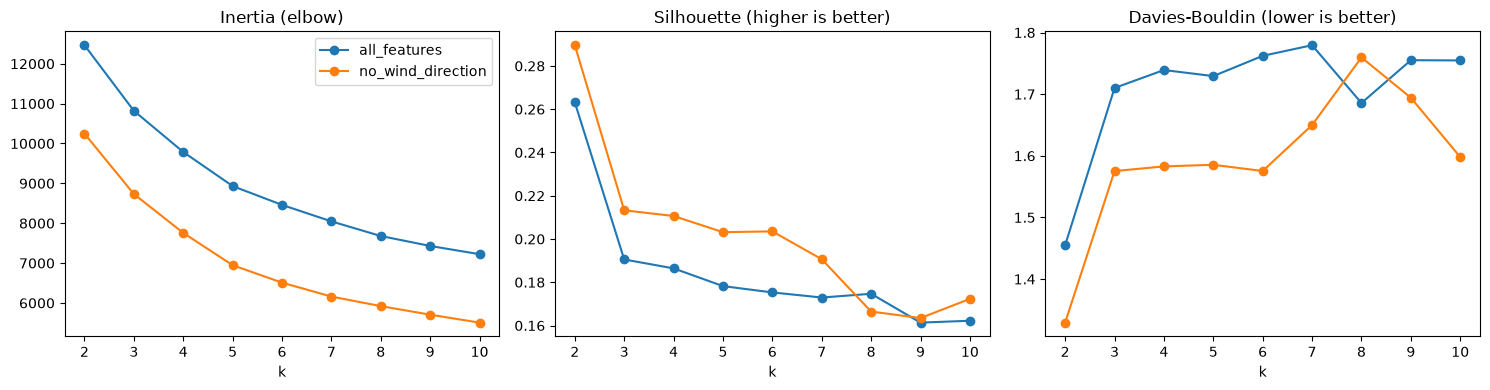

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name, g in res.groupby("variant"):
    axes[0].plot(g["k"], g["inertia"], marker="o", label=name)
    axes[1].plot(g["k"], g["silhouette"], marker="o", label=name)
    axes[2].plot(g["k"], g["davies_bouldin"], marker="o", label=name)
axes[0].set_title("Inertia (elbow)")
axes[1].set_title("Silhouette (higher is better)")
axes[2].set_title("Davies-Bouldin (lower is better)")
for a in axes: a.set_xlabel("k")
axes[0].legend(); plt.tight_layout(); plt.show()

## 4. Stability across random starts
Adjusted Rand Index between runs with different seeds. 1.0 means identical clusters every time.

In [5]:
def stability(data, k, n=10):
    base = KMeans(n_clusters=k, n_init=1, random_state=0).fit(data).labels_
    return np.mean([adjusted_rand_score(base, KMeans(n_clusters=k, n_init=1, random_state=s).fit(data).labels_)
                    for s in range(1, n + 1)])

for k in range(2, 9):
    print(k, round(stability(X, k), 3))

2 1.0
3 0.943
4 0.401
5 0.661
6 0.785
7 0.757
8 0.649


## 5. Stability for both variants
k=5 without wind direction is very stable (0.97). k=4 with wind direction is unstable (0.40).

In [6]:
# stability for the no-wind variant too
Xn = X.drop(columns=["wind_dir_sin", "wind_dir_cos"])
for k in range(2, 9):
    print(k, "all:", round(stability(X, k), 3), " no-wind:", round(stability(Xn, k), 3))

2 all: 1.0  no-wind: 0.993
3 all: 0.943  no-wind: 0.876
4 all: 0.401  no-wind: 0.774
5 all: 0.661  no-wind: 0.974
6 all: 0.785  no-wind: 0.691
7 all: 0.757  no-wind: 0.655
8 all: 0.649  no-wind: 0.68


## 6. Profile the candidate solutions (k = 3, 5, 6)
Raw averages per cluster, month distribution, and year distribution. The year table is an era check: no cluster should sit in a single year.

In [7]:
feat = pd.read_csv(BASE / "data" / "features" / "delhi_features.csv", parse_dates=["Date"], index_col="Date")
ctx = pd.read_csv(BASE / "data" / "features" / "delhi_context.csv", parse_dates=["Date"], index_col="Date")
raw = feat.drop(columns=["wind_dir_sin", "wind_dir_cos"])

for k in [3, 5, 6]:
    labels = KMeans(n_clusters=k, n_init=20, random_state=42).fit_predict(Xn)
    lab = pd.Series(labels, index=Xn.index, name="cluster")
    prof = raw.groupby(lab).mean().round(2)
    prof["days"] = lab.value_counts().sort_index()
    prof["AQI"] = ctx["AQI"].groupby(lab).mean().round(0)
    print(f"\n===== k = {k} =====")
    print(prof.T)
    print(pd.crosstab(lab, ctx["month"]))
    print(pd.crosstab(lab, ctx["year"]))      # era check: no cluster should be one year only


===== k = 3 =====
cluster          0       1       2
PM2.5       103.63   47.59  208.22
PM10        249.02  115.20  337.21
NO           36.38   14.29   67.68
NO2          52.92   28.52   63.18
NH3          39.00   32.94   51.40
SO2          20.02   10.90   17.29
O3           46.47   36.79   42.01
CO            1.11    0.89    1.76
Benzene       3.16    1.84    5.81
PM_ratio      0.43    0.43    0.61
temp         26.36   27.86   16.71
rain          0.27    3.68    0.32
wind_speed   17.54   16.35   12.12
days        427.00  382.00  386.00
AQI         257.00  131.00  370.00
month     1   2   3   4   5   6   7   8   9   10  11   12
cluster                                                  
0         16  40  91  81  90  37   1   0   5  42  16    8
1          6  11  25  36  32  60  62  62  60  20   4    4
2        101  59   8   3   2   0   0   0   0  31  70  112
year     2016  2017  2018  2019  2020
cluster                              
0           2   132   125   133    35
1           0    

## 7. Robustness check for k=5
Re-cluster after dropping SO2 (and then NO, NO2). Agreement with the original (ARI) is 0.84 without SO2, and no cluster is concentrated in one year.

In [8]:
from sklearn.metrics import adjusted_rand_score
ctx = pd.read_csv(BASE / "data" / "features" / "delhi_context.csv", parse_dates=["Date"], index_col="Date")

base_lab = KMeans(n_clusters=5, n_init=20, random_state=42).fit_predict(Xn)

# does k=5 survive dropping the columns that shift between 2017 and 2018?
for drop in [["SO2"], ["SO2", "NO"], ["SO2", "NO", "NO2"]]:
    lab2 = KMeans(n_clusters=5, n_init=20, random_state=42).fit_predict(Xn.drop(columns=drop))
    ct = pd.crosstab(pd.Series(lab2, index=Xn.index, name="c"), ctx["year"])
    top_share = (ct.max(axis=1) / ct.sum(axis=1)).round(2).tolist()
    print(drop, "ARI vs original:", round(adjusted_rand_score(base_lab, lab2), 3),
          "| largest single-year share per cluster:", top_share)

# step check: monthly means around the suspected shift
print(feat[["SO2", "NO", "NO2", "PM2.5"]].resample("MS").mean().round(1).loc["2017-01":"2018-12"])

# preview of validation: where do lockdown and Diwali days fall?
lab = pd.Series(base_lab, index=Xn.index, name="cluster")
print(pd.crosstab(lab, ctx["lockdown"]))
print(pd.crosstab(lab, ctx["diwali_window"]))

['SO2'] ARI vs original: 0.843 | largest single-year share per cluster: [0.47, 0.31, 0.37, 0.34, 0.35]
['SO2', 'NO'] ARI vs original: 0.755 | largest single-year share per cluster: [0.38, 0.36, 0.31, 0.35, 0.45]
['SO2', 'NO', 'NO2'] ARI vs original: 0.621 | largest single-year share per cluster: [0.38, 0.37, 0.45, 0.36, 0.33]
             SO2    NO   NO2  PM2.5
Date                               
2017-01-01  21.5  84.8  67.9  194.4
2017-02-01  19.7  85.1  69.4  144.3
2017-03-01  22.0  55.6  58.5  109.2
2017-04-01  34.4  71.2  80.3  117.3
2017-05-01  42.5  53.2  69.6  129.6
2017-06-01  21.8  64.5  90.5   93.6
2017-07-01   NaN   NaN   NaN    NaN
2017-08-01   NaN   NaN   NaN    NaN
2017-09-01   6.7  31.9  28.6   77.2
2017-10-01  18.3  40.5  47.2  146.7
2017-11-01  17.4  48.8  60.7  249.8
2017-12-01  19.5  49.4  56.6  189.3
2018-01-01  16.0  38.3  51.8  189.8
2018-02-01  13.5  39.8  57.4  137.9
2018-03-01  16.0  30.0  46.6   99.3
2018-04-01  14.7  26.7  49.0   90.5
2018-05-01  12.5  26.6  

## 8. Final model, saved labels and 2D view
k=5, wind direction excluded. Cluster numbers: 0 monsoon washout, 1 moderate winter smog, 2 pre-monsoon dust, 3 severe stagnant winter smog, 4 warm and cleaner. The picture shows a continuous cloud, not separate islands.

                rain  PM2.5  temp
kmeans_cluster                   
0                7.6   38.3  27.4
1                0.4  129.0  17.5
2                0.2  111.3  29.7
3                0.2  245.2  17.1
4                0.3   60.9  29.1


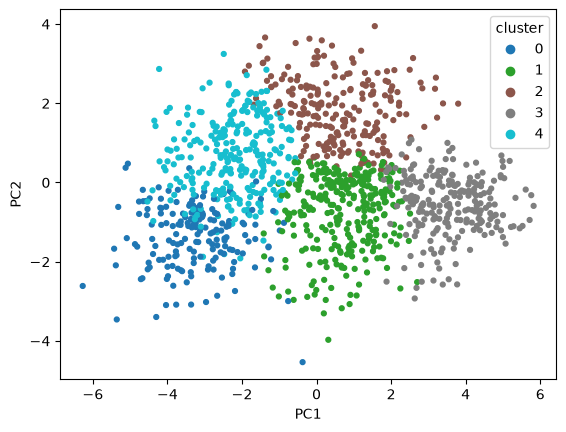

In [9]:
import joblib
from sklearn.decomposition import PCA

# same settings as the profiling run, so cluster numbers match the profile table
km = KMeans(n_clusters=5, n_init=20, random_state=42).fit(Xn)
labels = pd.Series(km.labels_, index=Xn.index, name="kmeans_cluster")

# check the numbering still matches (cluster 0 should have the most rain)
print(feat.drop(columns=["wind_dir_sin", "wind_dir_cos"]).groupby(labels)[["rain", "PM2.5", "temp"]].mean().round(1))

# save
(BASE / "data" / "results").mkdir(parents=True, exist_ok=True)
labels.to_csv(BASE / "data" / "results" / "kmeans_labels.csv")
joblib.dump(km, BASE / "models" / "kmeans_k5.pkl")

# 2D picture of the clusters
p = PCA(n_components=2).fit_transform(Xn)
sc = plt.scatter(p[:, 0], p[:, 1], c=labels, cmap="tab10", s=12)
plt.legend(*sc.legend_elements(), title="cluster")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.show()

## 9. Validation: lockdown and Diwali
Lockdown days: 88% fall in cluster 4 in 2020, while the same calendar window in other years is mostly cluster 2 (dust). PM2.5 spikes the day after Diwali in all three years.

In [10]:
# lockdown baseline: the same calendar window (25 Mar - 31 May) in every year
md = ctx.index.strftime("%m-%d")
window = (md >= "03-25") & (md <= "05-31")
print(pd.crosstab(ctx.loc[window, "year"], labels[window], normalize="index").round(2))

# Diwali: actual PM2.5 for 4 days before to 4 days after each date
for d in pd.to_datetime(["2017-10-19", "2018-11-07", "2019-10-27"]):
    print(d.date(), feat["PM2.5"].loc[d - pd.Timedelta(days=4): d + pd.Timedelta(days=4)].round(0).tolist())

kmeans_cluster     0     1     2     4
year                                  
2017            0.00  0.03  0.96  0.01
2018            0.01  0.01  0.59  0.38
2019            0.01  0.01  0.76  0.21
2020            0.09  0.00  0.03  0.88
2017-10-19 [148.0, 153.0, 122.0, 152.0, 176.0, 427.0, 213.0, 146.0, 163.0]
2018-11-07 [160.0, 97.0, 362.0, 178.0, 175.0, 420.0, 301.0, 289.0, 257.0]
2019-10-27 [122.0, 174.0, 130.0, 149.0, 199.0, 301.0, 288.0, 279.0, 314.0]


## Conclusion
KMeans with k=5 (wind direction excluded) gives stable, interpretable groups (stability 0.97, silhouette about 0.20).
Regimes: monsoon washout, moderate winter smog, severe stagnant winter smog, pre-monsoon dust, warm cleaner days.
k=6 was rejected because one cluster consisted almost entirely of 2017 days (a data-era artifact).
The clusters form a continuum, so they are tendencies, not sharp categories.
Validation: lockdown days shift from the dust regime to the cleaner regime in 2020; PM2.5 spikes the day after Diwali in all three years but KMeans does not isolate it.
Limitations: SO2 anomaly in spring 2017; weather differs between years.